Required Packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pulp

In [2]:
snowboards = ["Normal", "Deluxe"]
profit = [300, 400]
roughing = [20, 40]
polishing = [2/3, 1]


# The roughing equipment is available for 1000 minutes per week 
# the polishing equipment for 800 minutes per week
# minimum 18 normal snowboards must be produced per week

In [3]:
def solve_ski_patrol(snowboards, profit, roughing, polishing):
    profit = np.asarray(profit, dtype=float)
    roughing = np.asarray(roughing, dtype=float)
    polishing = np.asarray(polishing, dtype=float)

    model = pulp.LpProblem("Ski_patrol", pulp.LpMaximize)

    x = model.add_variable_dict("x", snowboards, lowBound=0, cat="Continuous")

    model += pulp.lpSum(profit[i] * x[s] for i, s in enumerate(snowboards))

    # constraints
    model += pulp.lpSum(roughing[i] * x[s] for i, s in enumerate(snowboards)) <= 1000, "Roughing"
    model += pulp.lpSum(polishing[i] * x[s] for i, s in enumerate(snowboards)) <= 800, "Polishing"
    model += x[snowboards[0]] >= 18, "Minimum_Normal"

    result = model.solve(pulp.HiGHS(msg=False))
    return model, x, result

In [4]:
model, x, result = solve_ski_patrol(snowboards, profit, roughing, polishing)
print(result.status_str, result.objective)
print({s: x[s].value() for s in snowboards})

Optimal 15000.0
{'Normal': 50.0, 'Deluxe': 0.0}


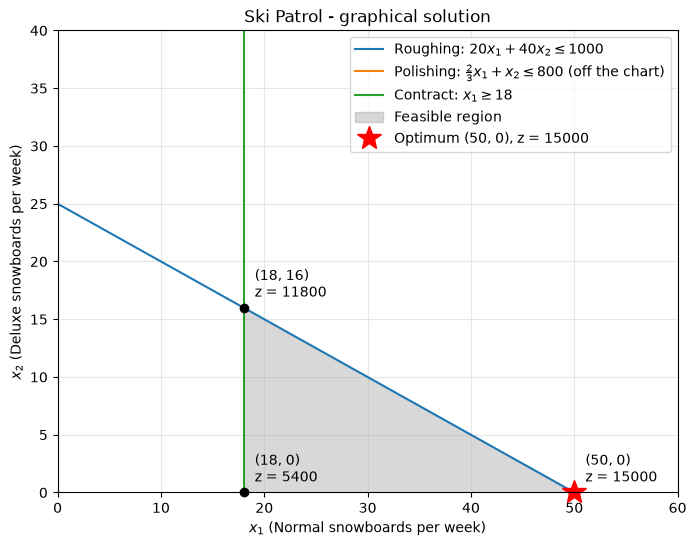

In [5]:
x1 = np.linspace(0, 60, 400)

# Each constraint written as x2 = ... (its boundary line)
roughing = 25 - x1 / 2            # 20*x1 + 40*x2 <= 1000
polishing = 800 - 2 * x1 / 3      # (2/3)*x1 + x2 <= 800

fig, ax = plt.subplots(figsize=(8, 6))

# 1. Constraint boundary lines
ax.plot(x1, roughing, label=r"Roughing: $20x_1 + 40x_2 \leq 1000$")
ax.plot(x1, polishing, label=r"Polishing: $\frac{2}{3}x_1 + x_2 \leq 800$ (off the chart)")
ax.axvline(18, color="tab:green", label=r"Contract: $x_1 \geq 18$")

# 2. Feasible region: below the roughing line, right of x1 = 18, and x2 >= 0
x1_feasible = np.linspace(18, 50, 200)
upper = np.minimum(25 - x1_feasible / 2, 800 - 2 * x1_feasible / 3)
ax.fill_between(x1_feasible, 0, upper, color="grey", alpha=0.3, label="Feasible region")

# 3. Corner points of the feasible region and the profit at each
corners = [(18, 0), (50, 0), (18, 16)]
for cx, cy in corners:
    z = 300 * cx + 400 * cy
    ax.plot(cx, cy, "ko", clip_on=False)
    ax.annotate(f"({cx}, {cy})\nz = {z}", (cx, cy), textcoords="offset points", xytext=(8, 8))


# 4. Optimum
ax.plot(50, 0, "r*", markersize=18, clip_on=False, label="Optimum (50, 0), z = 15000")

ax.set_xlim(0, 60)
ax.set_ylim(0, 40)
ax.set_xlabel("$x_1$ (Normal snowboards per week)")
ax.set_ylabel("$x_2$ (Deluxe snowboards per week)")
ax.set_title("Ski Patrol - graphical solution")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.show()